# PathSnap - Exploratory Data Analysis (Samyak, PES2UG24CS436)
Partitions used: **train (80 trips)** and **student_test (10 trips)**. The evaluator partition is never opened here.
Each section says which partition it uses.

In [1]:
import sys, os
sys.path.append("..")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, networkx as nx
from matplotlib.collections import LineCollection
from src.common.io import list_trips, trip_dir, load_trip, load_track
from src.common.geo import haversine_m
FIG, RES = "../results/figures/", "../results/"
PARTS = ["train", "student_test"]
pd.set_option("display.width", 160)

## 1. Inventory (train + student_test)

In [2]:
rows = []
for part in PARTS:
    for tid in list_trips(part):
        d = trip_dir(part, tid)
        t = load_trip(d)
        tr = t["track"]
        step = haversine_m(tr.lon.values[:-1], tr.lat.values[:-1], tr.lon.values[1:], tr.lat.values[1:])
        rows.append(dict(
            partition=part, trip_id=tid, n_points=len(tr), n_nodes=len(t["nodes"]), n_arcs=len(t["arcs"]),
            n_route_arcs=len(t["route"]) if t["route"] else 0,
            track_kb=os.path.getsize(d / f"{tid}.track") / 1024, nodes_kb=os.path.getsize(d / f"{tid}.nodes") / 1024,
            arcs_kb=os.path.getsize(d / f"{tid}.arcs") / 1024, route_kb=os.path.getsize(d / f"{tid}.route") / 1024,
            length_km=step.sum() / 1000, duration_min=(tr.t.iloc[-1] - tr.t.iloc[0]) / 60,
            start_lon=tr.lon.iloc[0], start_lat=tr.lat.iloc[0]))
inv = pd.DataFrame(rows)
inv.to_csv(RES + "eda_inventory.csv", index=False)
inv.groupby("partition")[["n_points", "n_nodes", "n_arcs", "n_route_arcs", "length_km", "duration_min"]].agg(["count", "min", "median", "max"]).round(1).T

partition            student_test     train
n_points     count           10.0      80.0
             min            262.0     361.0
             median        1420.0    1529.0
             max           3958.0   19313.0
n_nodes      count           10.0      80.0
             min           1770.0     299.0
             median        6596.5    9608.0
             max          26635.0  155003.0
n_arcs       count           10.0      80.0
             min           3577.0     649.0
             median       13145.0   19526.5
             max          56027.0  307392.0
n_route_arcs count           10.0      80.0
             min             95.0      59.0
             median         250.0     280.0
             max           1323.0    2266.0
length_km    count           10.0      80.0
             min              5.5       6.3
             median          20.9      24.1
             max             71.7     169.3
duration_min count           10.0      80.0
             min              4.4       7.5
             median          30.2      28.5
             max             66.7    2567.2

## 2. Missing / invalid values (train + student_test)

In [3]:
q = []
for part in PARTS:
    for tid in list_trips(part):
        tr = load_track(trip_dir(part, tid))
        dt = tr.t.diff().dropna()
        q.append(dict(partition=part, trip_id=tid,
                      nan_values=int(tr.isna().sum().sum()),
                      out_of_range=int((~tr.lon.between(-180, 180) | ~tr.lat.between(-90, 90)).sum()),
                      duplicate_t=int(tr.t.duplicated().sum()),
                      non_increasing_t=int((dt <= 0).sum())))
quality = pd.DataFrame(q)
quality.to_csv(RES + "eda_quality.csv", index=False)
quality.groupby("partition")[["nan_values", "out_of_range", "duplicate_t", "non_increasing_t"]].sum()

,nan_values,out_of_range,duplicate_t,non_increasing_t
partition,,,,
student_test,0,0,0,0
train,0,0,0,0


## 3. Sampling intervals (train + student_test)

share of steps exactly 1 s: {'student_test': 0.9862, 'train': 0.965}
trips with a gap >  10 s: {'student_test': 2, 'train': 40}
trips with a gap >  60 s: {'student_test': 1, 'train': 22}
trips with a gap > 300 s: {'train': 11}


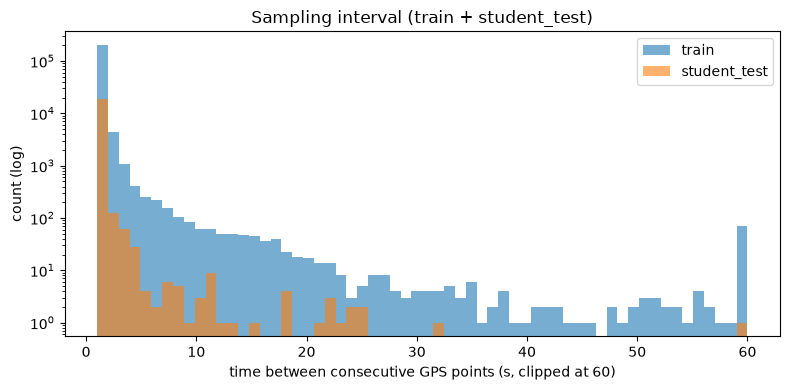

,partition,trip_id,share_dt_1s,max_gap_s,gaps_over_10s
72,train,00000090,0.581308,153064.0,6
61,train,00000078,0.755158,52810.0,25
55,train,00000069,0.989351,2658.0,2
16,train,00000021,0.999620,2161.0,2
8,train,00000011,0.999646,909.0,1
34,train,00000042,0.989532,670.0,37
64,train,00000081,0.719826,536.0,86
18,train,00000024,0.971250,458.0,2


In [4]:
dts, gap_rows = [], []
for part in PARTS:
    for tid in list_trips(part):
        dt = load_track(trip_dir(part, tid)).t.diff().dropna().values
        dts.append(pd.DataFrame({"partition": part, "dt": dt}))
        gap_rows.append(dict(partition=part, trip_id=tid, share_dt_1s=(dt == 1).mean(), max_gap_s=dt.max(),
                             gaps_over_10s=(dt > 10).sum()))
dts = pd.concat(dts); gaps = pd.DataFrame(gap_rows)
print("share of steps exactly 1 s:", dts.groupby("partition").dt.apply(lambda s: round((s == 1).mean(), 4)).to_dict())
for th in [10, 60, 300]:
    print(f"trips with a gap > {th:>3} s:", gaps[gaps.max_gap_s > th].groupby("partition").size().to_dict())
fig, ax = plt.subplots(figsize=(8, 4))
for part in PARTS:
    ax.hist(dts[dts.partition == part].dt.clip(upper=60), bins=60, log=True, alpha=0.6, label=part)
ax.set(xlabel="time between consecutive GPS points (s, clipped at 60)", ylabel="count (log)", title="Sampling interval (train + student_test)")
ax.legend(); plt.tight_layout(); plt.savefig(FIG + "eda_dt_hist.png", dpi=130); plt.show()
gaps.sort_values("max_gap_s", ascending=False).head(8)

## 4. Speed, jumps, trip size (train + student_test)

median speed m/s: {'student_test': 14.1, 'train': 11.1}
jumps > 60 m/s: {'student_test': 2, 'train': 546} in trips: 20


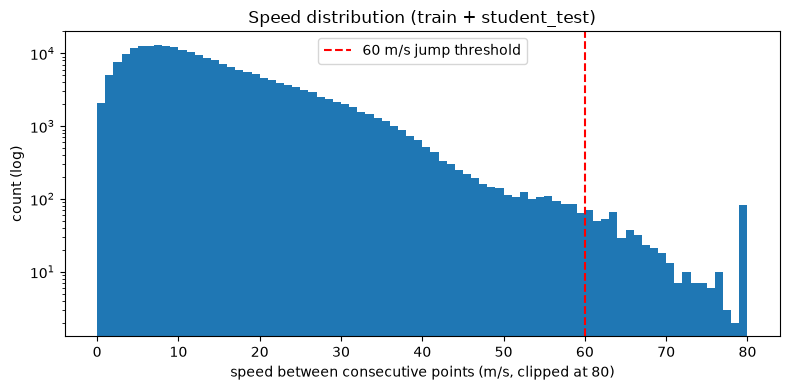

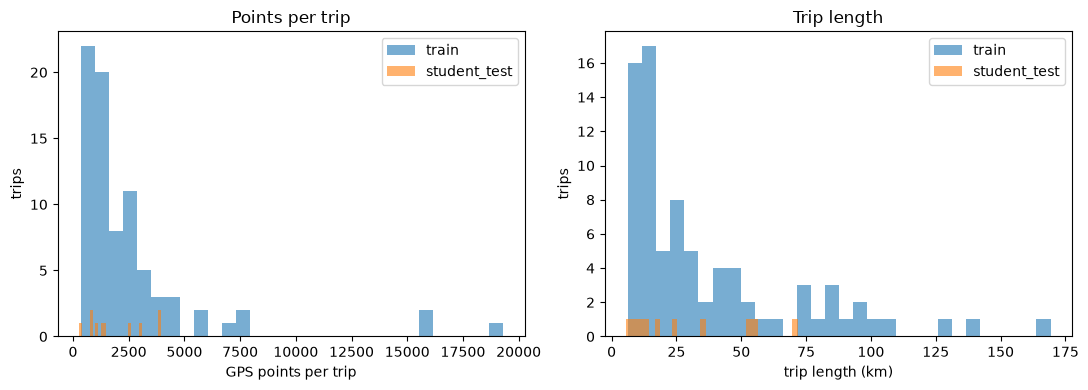

In [5]:
sp = []
for part in PARTS:
    for tid in list_trips(part):
        tr = load_track(trip_dir(part, tid))
        dt = tr.t.diff().values[1:]
        step = haversine_m(tr.lon.values[:-1], tr.lat.values[:-1], tr.lon.values[1:], tr.lat.values[1:])
        ok = dt > 0
        sp.append(pd.DataFrame({"partition": part, "trip_id": tid, "speed": step[ok] / dt[ok]}))
sp = pd.concat(sp)
print("median speed m/s:", sp.groupby("partition").speed.median().round(1).to_dict())
print("jumps > 60 m/s:", sp[sp.speed > 60].groupby("partition").size().to_dict(),
      "in trips:", sp[sp.speed > 60].trip_id.nunique())
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(sp.speed.clip(upper=80), bins=80, log=True, color="tab:blue")
ax.axvline(60, color="red", ls="--", label="60 m/s jump threshold")
ax.set(xlabel="speed between consecutive points (m/s, clipped at 80)", ylabel="count (log)", title="Speed distribution (train + student_test)")
ax.legend(); plt.tight_layout(); plt.savefig(FIG + "eda_speed_hist.png", dpi=130); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for part in PARTS:
    s = inv[inv.partition == part]
    ax[0].hist(s.n_points, bins=30, alpha=0.6, label=part)
    ax[1].hist(s.length_km, bins=30, alpha=0.6, label=part)
ax[0].set(xlabel="GPS points per trip", ylabel="trips", title="Points per trip"); ax[0].legend()
ax[1].set(xlabel="trip length (km)", ylabel="trips", title="Trip length"); ax[1].legend()
plt.tight_layout(); plt.savefig(FIG + "eda_trip_stats.png", dpi=130); plt.show()

## 5. Geographic extent (train + student_test)
Trips are spread across the world, one city per trip. Degrees are not metres, and no single UTM zone covers all trips,
so every trip is projected to local metres around its own first point (`src/common/geo.py`).

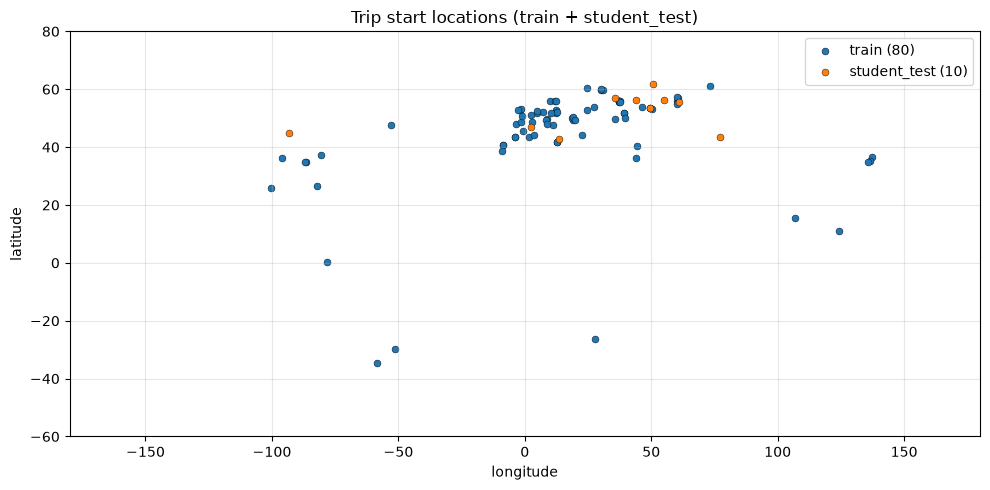

distinct ~1-degree cells: 75


In [6]:
fig, ax = plt.subplots(figsize=(10, 5))
for part, c in zip(PARTS, ["tab:blue", "tab:orange"]):
    s = inv[inv.partition == part]
    ax.scatter(s.start_lon, s.start_lat, s=25, c=c, label=f"{part} ({len(s)})", edgecolor="k", lw=0.3)
ax.set(xlim=(-180, 180), ylim=(-60, 80), xlabel="longitude", ylabel="latitude", title="Trip start locations (train + student_test)")
ax.grid(alpha=0.3); ax.legend(); plt.tight_layout(); plt.savefig(FIG + "eda_trip_locations.png", dpi=130); plt.show()
print("distinct ~1-degree cells:", inv[["start_lon", "start_lat"]].round(0).drop_duplicates().shape[0])

## 6. Road network size and connectivity (train + student_test)

partition                 student_test       train
n_nodes           min         1770.000     299.000
                  median      6596.500    9608.000
                  max        26635.000  155003.000
n_arcs            min         3575.000     649.000
                  median     13112.000   19524.500
                  max        55998.000  307263.000
weak_components   min            5.000       1.000
                  median        11.000      20.000
                  max          100.000     421.000
largest_wcc_share min            0.874       0.693
                  median         0.971       0.981
                  max            0.991       1.000
largest_scc_share min            0.817       0.636
                  median         0.961       0.964
                  max            0.984       1.000
isolated_nodes    min            0.000       0.000
                  median         0.000       0.000
                  max            0.000       0.000
two_way_share     min            0.855       0.351
                  median         0.932       0.951
                  max            0.996       1.000

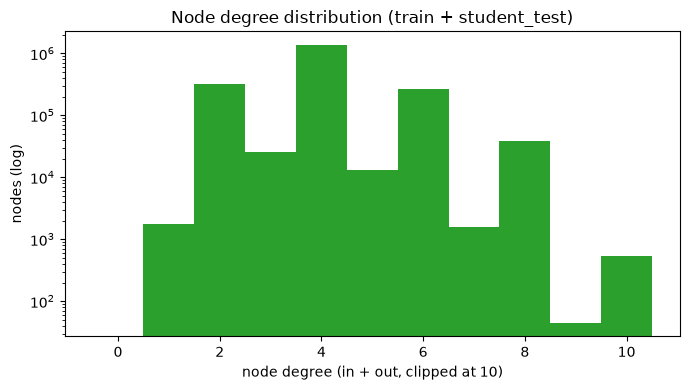

In [7]:
net, degs = [], []
for part in PARTS:
    for tid in list_trips(part):
        t = load_trip(trip_dir(part, tid))
        ar = t["arcs"]
        G = nx.DiGraph()
        G.add_nodes_from(range(len(t["nodes"])))
        G.add_edges_from(zip(ar.from_node, ar.to_node))
        wcc = [len(c) for c in nx.weakly_connected_components(G)]
        scc = [len(c) for c in nx.strongly_connected_components(G)]
        pairs = set(zip(ar.from_node, ar.to_node))
        deg = np.array([d for _, d in G.degree()])
        degs.append(deg)
        net.append(dict(partition=part, trip_id=tid, n_nodes=G.number_of_nodes(), n_arcs=G.number_of_edges(),
                        weak_components=len(wcc), largest_wcc_share=max(wcc) / len(G),
                        strong_components=len(scc), largest_scc_share=max(scc) / len(G),
                        isolated_nodes=int((deg == 0).sum()),
                        two_way_share=np.mean([(b, a) in pairs for a, b in pairs])))
net = pd.DataFrame(net)
net.to_csv(RES + "eda_network.csv", index=False)
display(net.groupby("partition")[["n_nodes", "n_arcs", "weak_components", "largest_wcc_share", "largest_scc_share",
                                 "isolated_nodes", "two_way_share"]].agg(["min", "median", "max"]).round(3).T)
deg = np.concatenate(degs)
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(deg.clip(max=10), bins=np.arange(0, 12) - 0.5, log=True, color="tab:green")
ax.set(xlabel="node degree (in + out, clipped at 10)", ylabel="nodes (log)", title="Node degree distribution (train + student_test)")
plt.tight_layout(); plt.savefig(FIG + "eda_degree_hist.png", dpi=130); plt.show()

## 7. Reference route checks + GPS noise (train + student_test)

route contiguity (mean): {'student_test': 0.9997, 'train': 0.9993}
labelled share of GPS points: {'student_test': 0.999, 'train': 0.888}


,partition,trip_id,route_contiguity,route_km,labelled_share
44,train,00000054,1.000000,31.362913,0.105577
26,train,00000033,0.994048,6.379102,0.411191
1,train,00000002,0.996169,7.963175,0.880160
53,train,00000066,1.000000,72.846109,0.909827
35,train,00000043,1.000000,59.224683,0.928079


distance GPS -> labelled arc (m): median {'student_test': 5.2, 'train': 4.9} | 95th pct {'student_test': 16.7, 'train': 17.4}


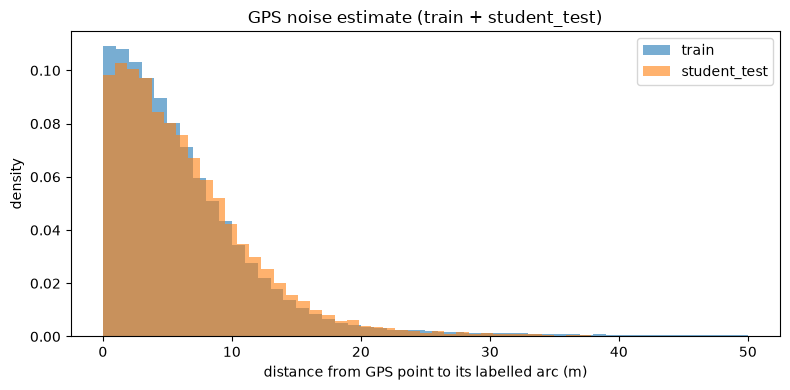

In [8]:
rc = []
for part in PARTS:
    for tid in list_trips(part):
        t = load_trip(trip_dir(part, tid))
        ar, nd, rt = t["arcs"], t["nodes"], np.array(t["route"])
        f, to = ar.from_node.values[rt], ar.to_node.values[rt]
        rc.append(dict(partition=part, trip_id=tid, route_contiguity=(to[:-1] == f[1:]).mean(),
                       route_km=haversine_m(nd.lon.values[f], nd.lat.values[f], nd.lon.values[to], nd.lat.values[to]).sum() / 1000))
rc = pd.DataFrame(rc)

pts = pd.concat([pd.read_parquet(f"../data/processed/{p}_points.parquet").assign(partition=p) for p in PARTS])
lab = pts.groupby(["partition", "trip_id"]).apply(lambda g: (g.true_arc >= 0).mean(), include_groups=False).rename("labelled_share").reset_index()
rc = rc.merge(lab, on=["partition", "trip_id"])
print("route contiguity (mean):", rc.groupby("partition").route_contiguity.mean().round(4).to_dict())
print("labelled share of GPS points:", (pts.true_arc >= 0).groupby(pts.partition).mean().round(3).to_dict())
display(rc.sort_values("labelled_share").head(5))   # 00000054 and 00000033 have routes that cover only part of the drive

d = pts[pts.true_arc >= 0]
print("distance GPS -> labelled arc (m): median", d.groupby("partition").label_dist.median().round(1).to_dict(),
      "| 95th pct", d.groupby("partition").label_dist.quantile(0.95).round(1).to_dict())
fig, ax = plt.subplots(figsize=(8, 4))
for part in PARTS:
    ax.hist(d[d.partition == part].label_dist, bins=50, alpha=0.6, density=True, label=part)
ax.set(xlabel="distance from GPS point to its labelled arc (m)", ylabel="density", title="GPS noise estimate (train + student_test)")
ax.legend(); plt.tight_layout(); plt.savefig(FIG + "eda_label_dist_hist.png", dpi=130); plt.show()

## 8. Trips over their road network (train)

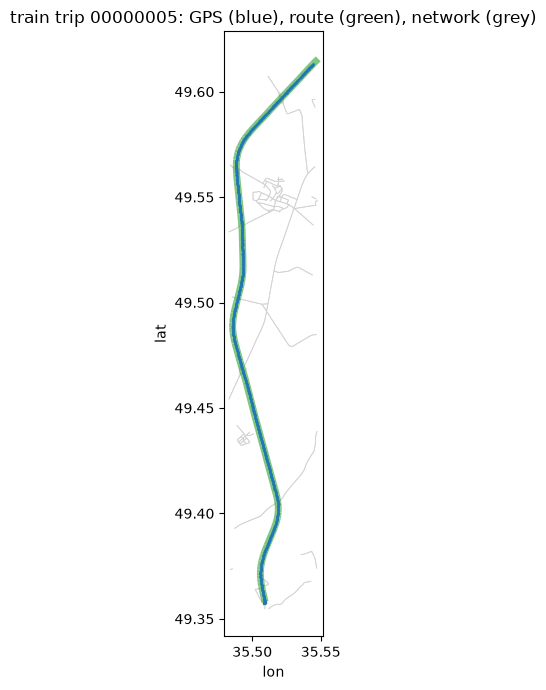

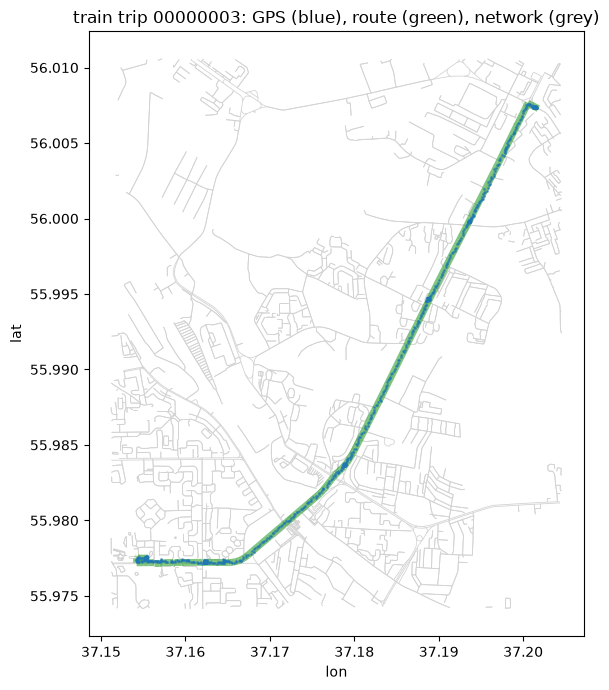

In [9]:
def plot_trip(part, tid, ax, buf=0.003):
    t = load_trip(trip_dir(part, tid)); tr, nd, ar = t["track"], t["nodes"], t["arcs"]
    inside = (nd.lon.between(tr.lon.min() - buf, tr.lon.max() + buf) & nd.lat.between(tr.lat.min() - buf, tr.lat.max() + buf)).values
    a = ar[inside[ar.from_node.values] & inside[ar.to_node.values]]
    seg = lambda x: np.stack([nd.loc[x.from_node, ["lon", "lat"]].values, nd.loc[x.to_node, ["lon", "lat"]].values], axis=1)
    ax.add_collection(LineCollection(seg(a), colors="lightgrey", linewidths=0.6))
    ax.add_collection(LineCollection(seg(ar.loc[t["route"]]), colors="tab:green", linewidths=5, alpha=0.6))
    ax.scatter(tr.lon, tr.lat, s=1, c="tab:blue", alpha=0.6, zorder=3)
    ax.set_aspect(1 / np.cos(np.radians(tr.lat.mean())))
    ax.set(title=f"{part} trip {tid}: GPS (blue), route (green), network (grey)", xlabel="lon", ylabel="lat")
    ax.autoscale()

for tid in ["00000005", "00000003"]:
    fig, ax = plt.subplots(figsize=(7, 7))
    plot_trip("train", tid, ax)
    plt.tight_layout(); plt.savefig(FIG + f"eda_trip_{tid}_network.png", dpi=130); plt.show()

## 9. Interactive Folium map (student_test trip 00000007)

In [10]:
import folium
part, tid = "student_test", "00000007"
t = load_trip(trip_dir(part, tid)); tr, nd, ar = t["track"], t["nodes"], t["arcs"]
buf = 0.003
inside = (nd.lon.between(tr.lon.min() - buf, tr.lon.max() + buf) & nd.lat.between(tr.lat.min() - buf, tr.lat.max() + buf)).values
lines = lambda x: [[nd.loc[f, ["lat", "lon"]].tolist(), nd.loc[to, ["lat", "lon"]].tolist()] for f, to in zip(x.from_node, x.to_node)]

m = folium.Map(tiles="OpenStreetMap", control_scale=True)
g_net = folium.FeatureGroup("Road network (cropped)")
folium.PolyLine(lines(ar[inside[ar.from_node.values] & inside[ar.to_node.values]]), color="#888888", weight=1, opacity=0.6).add_to(g_net)
g_route = folium.FeatureGroup("Reference route")
folium.PolyLine(lines(ar.loc[t["route"]]), color="#2ca02c", weight=6, opacity=0.8).add_to(g_route)
g_gps = folium.FeatureGroup(f"GPS observations ({len(tr)})")
for lat, lon, ts in tr[["lat", "lon", "t"]].itertuples(index=False):
    folium.CircleMarker([lat, lon], radius=2, color="#1f77b4", fill=True, weight=0, fill_opacity=0.8, tooltip=f"t={ts:.0f}s").add_to(g_gps)
for g in (g_net, g_route, g_gps):
    g.add_to(m)
legend = ('<div style="position:fixed;bottom:30px;left:30px;z-index:9999;background:white;padding:8px 12px;border:1px solid #999;border-radius:6px;font-size:13px">'
          '<b>student_test 00000007</b><br><span style="color:#1f77b4">&#9679;</span> GPS observations<br>'
          '<span style="color:#2ca02c">&#9644;</span> Reference route<br><span style="color:#888">&#9644;</span> Road network</div>')
m.get_root().html.add_child(folium.Element(legend))
folium.LayerControl(collapsed=False).add_to(m)
m.fit_bounds([[tr.lat.min(), tr.lon.min()], [tr.lat.max(), tr.lon.max()]])
m.save(f"../results/maps/eda_trip_{tid}.html")
m

## 10. Data-quality notes & decisions
| Issue found (partition) | Decision |
|---|---|
| No NaN, out-of-range coordinates, duplicate or decreasing timestamps (train + student_test) | Keep the defensive checks in `clean_track`, but no rows are dropped in practice |
| Sampling is ~1 Hz (96.5% of train steps and 98.6% of student_test steps are exactly 1 s), but 40 train trips have gaps > 10 s and 11 have gaps > 300 s; train 00000090 has a 153,064 s (~42 h) gap | Flag `is_gap` (dt > 10 s) instead of deleting points; the HMM must loosen or restart transitions after gaps |
| 546 train steps faster than 60 m/s across 20 trips (median speed ~11 m/s) | Flag `is_jump`; keep the point so every GPS observation still gets a prediction |
| Trips are worldwide (75 distinct 1-degree cells) | Project each trip to local metres around its first point; no global UTM zone |
| Networks are large (up to 155k nodes) and not fully connected (largest weak component median 98%, min 69%) | Crop the network to the track bounding box + 300 m before candidate search; transitions must survive unreachable pairs (finite penalty) |
| Most roads are two-way (median 95% of arcs have a reverse arc) | Use `heading_diff` as a feature: distance alone cannot separate the two directions |
| Reference routes are contiguous (99.9%) but in train 00000054 (11% of points) and 00000033 (41%) the route covers only part of the drive | Points more than 50 m from their aligned route arc get label -1 and are excluded from training and accuracy (88.8% of train points and 99.9% of student_test points are labelled) |
| GPS noise: median 4.9 m, 95th percentile 17.4 m to the labelled arc (train) | A 50 m candidate radius covers the noise with margin (candidate miss rate 0.85% on train) |
